1. Imports + Load Data + Initial Inspection

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load data
df = pd.read_excel(r"C:\Users\ar085\Downloads\online+retail\Online Retail.xlsx")

# Standardize columns
df.columns = [
    "invoice_no", "stock_code", "description", "quantity",
    "invoice_date", "unit_price", "customer_id", "country"
]

# Data types
df["invoice_date"] = pd.to_datetime(df["invoice_date"])
df["invoice_no"] = df["invoice_no"].astype(str)
df["stock_code"] = df["stock_code"].astype(str)
df["customer_id"] = df["customer_id"].astype("Int64")

print(f"Shape: {df.shape}")
print(f"Customers: {df['customer_id'].nunique():,}")
print(f"Products: {df['stock_code'].nunique():,}")
print(f"Countries: {df['country'].nunique()}")
print(f"Duplicates: {df.duplicated().sum():,}")
print(f"Missing Customer IDs: {df['customer_id'].isna().sum():,}")
print(f"Date Range: {df['invoice_date'].min()} → {df['invoice_date'].max()}")

Shape: (541909, 8)
Customers: 4,372
Products: 4,070
Countries: 38
Duplicates: 5,268
Missing Customer IDs: 135,080
Date Range: 2010-12-01 08:26:00 → 2011-12-09 12:50:00


2. Data Quality + Cleaning

In [5]:
# Data quality flags
df["is_cancelled"] = df["invoice_no"].str.startswith("C")
df["revenue"] = df["quantity"] * df["unit_price"]

print("Cancelled invoices:", df["is_cancelled"].sum())
print("Negative quantities:", (df["quantity"] < 0).sum())
print("Non-positive prices:", (df["unit_price"] <= 0).sum())
print("Missing descriptions:", df["description"].isna().sum())

# Clean analytical dataset
clean_df = (
    df
    .drop_duplicates()
    .loc[
        (~df["is_cancelled"]) &
        (df["customer_id"].notna()) &
        (df["quantity"] > 0) &
        (df["unit_price"] > 0)
    ]
    .copy()
)

print(f"\nOriginal rows: {len(df):,}")
print(f"Clean rows: {len(clean_df):,}")
print(f"Removed rows: {len(df)-len(clean_df):,}")

Cancelled invoices: 9288
Negative quantities: 10624
Non-positive prices: 2517
Missing descriptions: 1454

Original rows: 541,909
Clean rows: 392,692
Removed rows: 149,217


3. Create Customers, Products & Transactions

In [6]:
# Transactions
transactions = clean_df[
    ["invoice_no", "stock_code", "invoice_date", "customer_id",
     "quantity", "unit_price", "revenue", "country"]
].rename(columns={
    "invoice_no": "transaction_id",
    "stock_code": "product_id"
})

# Customers
customers = (
    clean_df.groupby("customer_id")
    .agg(
        country=("country", "first"),
        first_purchase_date=("invoice_date", "min"),
        last_purchase_date=("invoice_date", "max"),
        total_spend=("revenue", "sum"),
        transaction_count=("invoice_no", "nunique"),
        total_items=("quantity", "sum")
    )
    .reset_index()
)

customers["avg_transaction_value"] = (
    customers["total_spend"] / customers["transaction_count"]
)

# Products
products = (
    clean_df[["stock_code", "description"]]
    .drop_duplicates()
    .rename(columns={"stock_code": "product_id"})
)

print("Transactions:", transactions.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)

Transactions: (392692, 8)
Customers: (4338, 8)
Products: (3897, 2)


4. Product Categories + Merchants

In [7]:
def categorize_product(description):
    d = str(description).upper()

    if any(x in d for x in ["BAG", "PURSE", "WALLET", "JEWEL", "NECKLACE"]):
        return "Fashion"
    elif any(x in d for x in ["CANDLE", "LANTERN", "LIGHT", "CUSHION"]):
        return "Home & Lifestyle"
    elif any(x in d for x in ["MUG", "CUP", "PLATE", "BOWL", "GLASS"]):
        return "Kitchen & Dining"
    elif any(x in d for x in ["TOY", "GAME", "CHILD", "DOLL"]):
        return "Kids & Games"
    elif any(x in d for x in ["CHRISTMAS", "EASTER", "PARTY"]):
        return "Seasonal"
    else:
        return "General Retail"

products["category"] = products["description"].apply(categorize_product)

merchant_mapping = {
    "Fashion": ("M001", "StyleHub"),
    "Home & Lifestyle": ("M002", "HomeLiving"),
    "Kitchen & Dining": ("M003", "KitchenWorld"),
    "Kids & Games": ("M004", "FunZone"),
    "Seasonal": ("M005", "SeasonalMart"),
    "General Retail": ("M006", "EverydayStore")
}

products["merchant_id"] = products["category"].map(
    lambda x: merchant_mapping[x][0]
)
products["merchant_name"] = products["category"].map(
    lambda x: merchant_mapping[x][1]
)

merchants = (
    products[["merchant_id", "merchant_name", "category"]]
    .drop_duplicates()
    .rename(columns={"category": "industry"})
)

print(merchants)

   merchant_id  merchant_name          industry
0         M002     HomeLiving  Home & Lifestyle
2         M003   KitchenWorld  Kitchen & Dining
3         M006  EverydayStore    General Retail
12        M004        FunZone      Kids & Games
38        M001       StyleHub           Fashion
46        M005   SeasonalMart          Seasonal


5. Customer RFM Segmentation

In [8]:
reference_date = clean_df["invoice_date"].max() + pd.Timedelta(days=1)

rfm = (
    clean_df.groupby("customer_id")
    .agg(
        recency=("invoice_date",
                 lambda x: (reference_date - x.max()).days),
        frequency=("invoice_no", "nunique"),
        monetary=("revenue", "sum")
    )
    .reset_index()
)

# RFM scores
rfm["R_score"] = pd.qcut(
    rfm["recency"], 5, labels=[5,4,3,2,1], duplicates="drop"
)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    5, labels=[1,2,3,4,5]
)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    5, labels=[1,2,3,4,5]
)

rfm["RFM_score"] = (
    rfm["R_score"].astype(int) +
    rfm["F_score"].astype(int) +
    rfm["M_score"].astype(int)
)

def segment_customer(score):
    if score >= 13:
        return "Champions"
    elif score >= 10:
        return "Loyal Customers"
    elif score >= 7:
        return "Potential Loyalists"
    elif score >= 5:
        return "At Risk"
    return "Dormant"

rfm["segment"] = rfm["RFM_score"].apply(segment_customer)

print(rfm["segment"].value_counts())

segment
Potential Loyalists    1088
Loyal Customers        1010
Champions               933
At Risk                 763
Dormant                 544
Name: count, dtype: int64


6. Create Offers

In [9]:
offers = pd.DataFrame({
    "offer_id": [f"O{i:03d}" for i in range(1, 7)],
    "merchant_id": ["M001", "M002", "M003", "M004", "M005", "M006"],
    "discount_pct": [10, 15, 10, 20, 15, 5],
    "min_spend": [50, 75, 40, 30, 60, 100],
    "offer_type": ["Discount"] * 6,
    "start_date": [pd.Timestamp("2011-01-01")] * 6,
    "end_date": [pd.Timestamp("2011-12-31")] * 6
})

offers

,offer_id,merchant_id,discount_pct,min_spend,offer_type,start_date,end_date
0,O001,M001,10,50,Discount,2011-01-01,2011-12-31
1,O002,M002,15,75,Discount,2011-01-01,2011-12-31
2,O003,M003,10,40,Discount,2011-01-01,2011-12-31
3,O004,M004,20,30,Discount,2011-01-01,2011-12-31
4,O005,M005,15,60,Discount,2011-01-01,2011-12-31
5,O006,M006,5,100,Discount,2011-01-01,2011-12-31


7. Customer Targeting + Redemption Simulation

In [10]:
np.random.seed(42)

# Customer-category spending
customer_category = (
    clean_df
    .merge(
        products[["product_id", "category", "merchant_id"]],
        left_on="stock_code",
        right_on="product_id",
        how="left"
    )
    .groupby(["customer_id", "category"])
    .agg(
        category_spend=("revenue", "sum"),
        category_transactions=("invoice_no", "nunique")
    )
    .reset_index()
)

# Preferred category for each customer
preferred_category = (
    customer_category
    .sort_values(
        ["customer_id", "category_spend"],
        ascending=[True, False]
    )
    .drop_duplicates("customer_id")
)

# Connect customer → merchant → offer
targeting = (
    preferred_category
    .merge(
        merchants,
        left_on="category",
        right_on="industry",
        how="left"
    )
    .merge(
        offers,
        on="merchant_id",
        how="left"
    )
)

targeting["targeted_date"] = pd.Timestamp("2011-06-01")

# Simulated redemption probability
targeting["redemption_probability"] = np.clip(
    0.05 +
    (targeting["category_spend"] /
     targeting["category_spend"].max()) * 0.30,
    0.03,
    0.60
)

# Simulated redemption
targeting["redeemed"] = np.random.binomial(
    1,
    targeting["redemption_probability"]
)

# Redemption table
redemptions = targeting[targeting["redeemed"] == 1].copy()

redemptions["redemption_id"] = [
    f"R{i:06d}" for i in range(1, len(redemptions) + 1)
]

redemptions["discount_amount"] = (
    redemptions["category_spend"] *
    redemptions["discount_pct"] / 100
)

print(f"Targeted customers: {targeting['customer_id'].nunique():,}")
print(f"Redemptions: {len(redemptions):,}")
print(
    f"Redemption rate: "
    f"{targeting['redeemed'].mean()*100:.2f}%"
)

Targeted customers: 4,338
Redemptions: 231
Redemption rate: 5.33%


8. Core Business Analytics

In [11]:
# Overall KPIs
total_revenue = clean_df["revenue"].sum()
total_customers = clean_df["customer_id"].nunique()
total_transactions = clean_df["invoice_no"].nunique()
redemption_rate = targeting["redeemed"].mean() * 100

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Customers: {total_customers:,}")
print(f"Transactions: {total_transactions:,}")
print(f"Offer Redemption Rate: {redemption_rate:.2f}%")

# Merchant performance
merchant_performance = (
    clean_df
    .merge(
        products[["product_id", "merchant_id"]],
        left_on="stock_code",
        right_on="product_id"
    )
    .merge(merchants, on="merchant_id")
    .groupby(["merchant_name", "industry"])
    .agg(
        revenue=("revenue", "sum"),
        transactions=("invoice_no", "nunique"),
        customers=("customer_id", "nunique")
    )
    .reset_index()
    .sort_values("revenue", ascending=False)
)

# Offer performance
offer_performance = (
    targeting.groupby(["offer_id", "discount_pct"])
    .agg(
        targeted=("customer_id", "nunique"),
        redeemed=("redeemed", "sum")
    )
    .reset_index()
)

offer_performance["redemption_rate"] = (
    offer_performance["redeemed"] /
    offer_performance["targeted"] * 100
)

# Segment performance
segment_performance = (
    targeting
    .merge(rfm[["customer_id", "segment"]], on="customer_id")
    .groupby("segment")
    .agg(
        customers=("customer_id", "nunique"),
        targeted=("offer_id", "count"),
        redemptions=("redeemed", "sum")
    )
    .reset_index()
)

segment_performance["redemption_rate"] = (
    segment_performance["redemptions"] /
    segment_performance["targeted"] * 100
)

display(merchant_performance)
display(offer_performance)
display(segment_performance)

Total Revenue: £8,887,208.89
Customers: 4,338
Transactions: 18,532
Offer Redemption Rate: 5.33%


,merchant_name,industry,revenue,transactions,customers
0,EverydayStore,General Retail,6578063.271,17645,4257
5,StyleHub,Fashion,1155206.750,9047,2819
2,HomeLiving,Home & Lifestyle,998294.343,10224,3281
3,KitchenWorld,Kitchen & Dining,553280.670,8612,2938
4,SeasonalMart,Seasonal,451416.950,7066,2809
1,FunZone,Kids & Games,306682.840,5389,2125


,offer_id,discount_pct,targeted,redeemed,redemption_rate
0,O001,10,199,10,5.025126
1,O002,15,207,12,5.797101
2,O003,10,53,0,0.000000
3,O004,20,11,1,9.090909
4,O005,15,50,3,6.000000
5,O006,5,3818,205,5.369303


,segment,customers,targeted,redemptions,redemption_rate
0,At Risk,763,763,45,5.897772
1,Champions,933,933,52,5.573419
2,Dormant,544,544,22,4.044118
3,Loyal Customers,1010,1010,57,5.643564
4,Potential Loyalists,1088,1088,55,5.055147


9. Visualizations

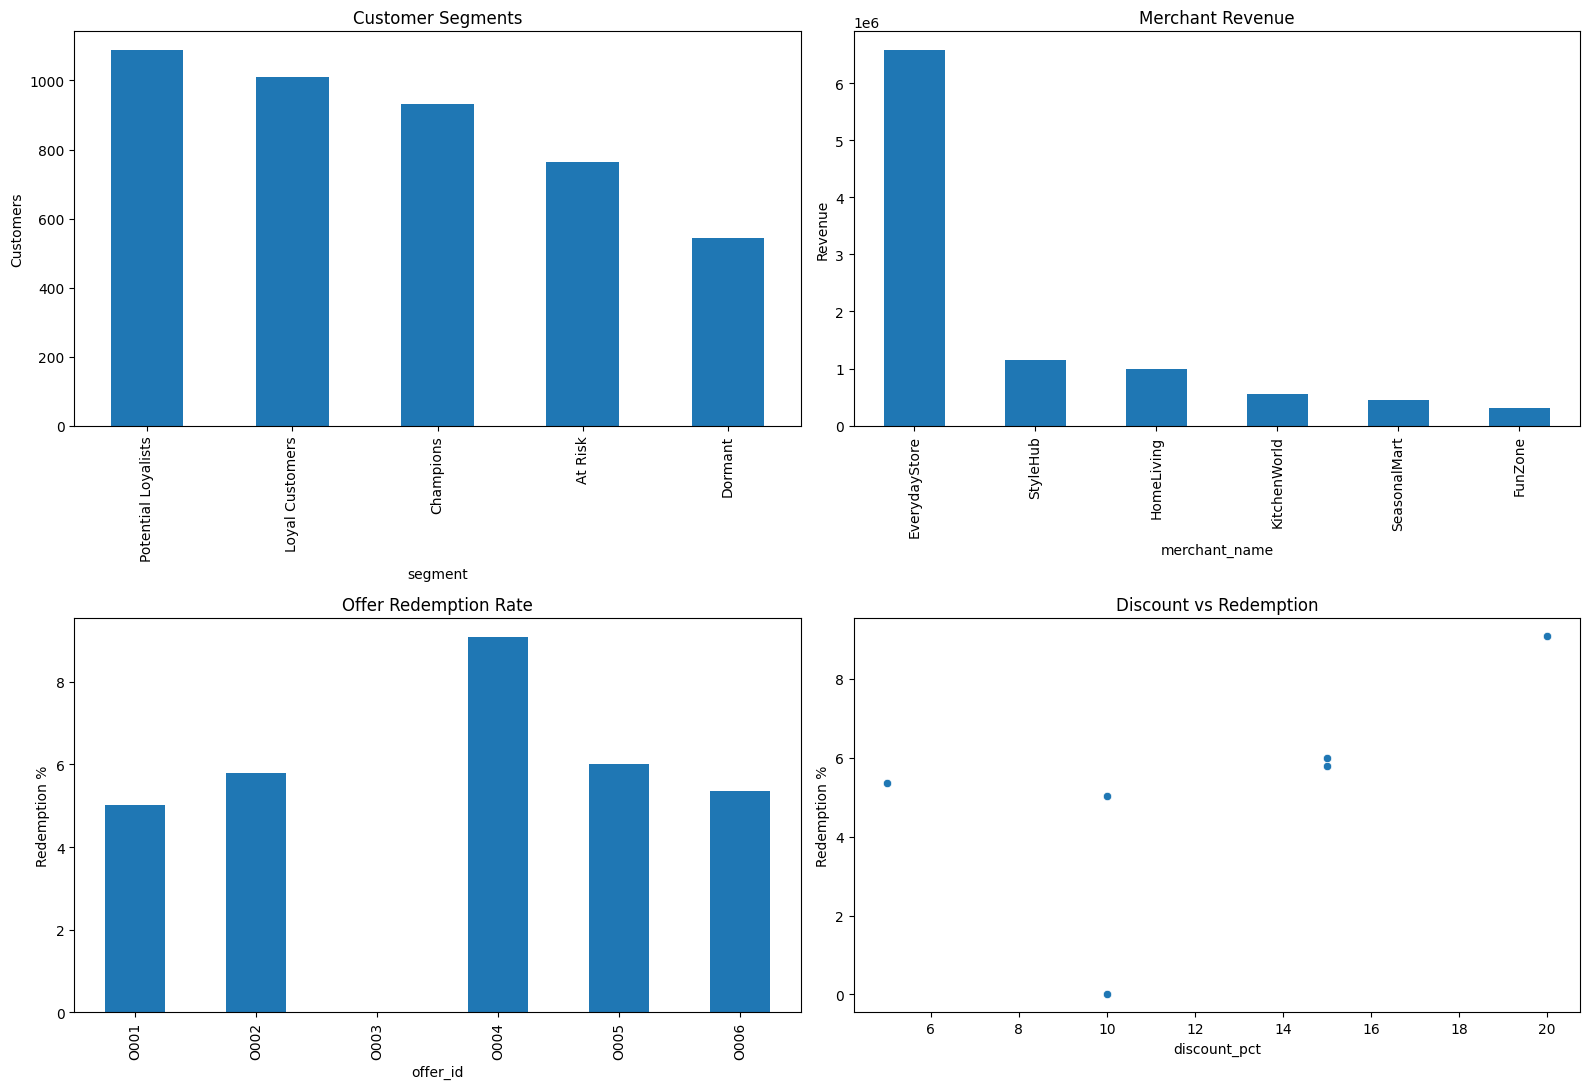

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Customer segments
rfm["segment"].value_counts().plot(
    kind="bar", ax=axes[0, 0]
)
axes[0, 0].set_title("Customer Segments")
axes[0, 0].set_ylabel("Customers")

# 2. Merchant revenue
merchant_performance.head(10).plot(
    x="merchant_name",
    y="revenue",
    kind="bar",
    ax=axes[0, 1],
    legend=False
)
axes[0, 1].set_title("Merchant Revenue")
axes[0, 1].set_ylabel("Revenue")

# 3. Offer redemption
offer_performance.plot(
    x="offer_id",
    y="redemption_rate",
    kind="bar",
    ax=axes[1, 0],
    legend=False
)
axes[1, 0].set_title("Offer Redemption Rate")
axes[1, 0].set_ylabel("Redemption %")

# 4. Discount vs redemption
sns.scatterplot(
    data=offer_performance,
    x="discount_pct",
    y="redemption_rate",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Discount vs Redemption")
axes[1, 1].set_ylabel("Redemption %")

plt.tight_layout()
plt.show()

10. Export Everything

In [13]:
os.makedirs("../output", exist_ok=True)

tables = {
    "customers": customers,
    "transactions": transactions,
    "products": products,
    "merchants": merchants,
    "offers": offers,
    "targeting": targeting,
    "redemptions": redemptions,
    "rfm": rfm,
    "merchant_performance": merchant_performance,
    "offer_performance": offer_performance,
    "segment_performance": segment_performance
}

for name, table in tables.items():
    table.to_csv(f"../output/{name}.csv", index=False)

print(f"Exported {len(tables)} tables successfully.")

Exported 11 tables successfully.


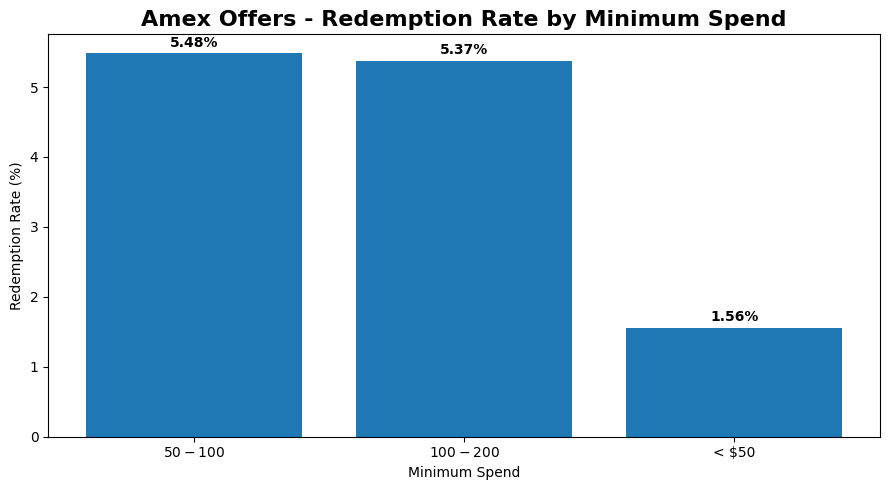

In [7]:
import matplotlib.pyplot as plt

buckets = ['$50-$100', '$100-$200', '< $50']
rates = [5.48, 5.37, 1.56]

plt.figure(figsize=(9, 5))
bars = plt.bar(buckets, rates)

plt.title('Amex Offers - Redemption Rate by Minimum Spend', fontsize=16, fontweight='bold')
plt.xlabel('Minimum Spend')
plt.ylabel('Redemption Rate (%)')

for bar, rate in zip(bars, rates):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.1,
        f'{rate:.2f}%',
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.savefig("../images/minimum_spend_optimization.png", dpi=300, bbox_inches="tight")
plt.show()